# Rozpoznawanie języka mowy: Spektrogramy Mel / MFCC + Prozodia + Regularized SVM

In [1]:
%load_ext autoreload
%autoreload 2

import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.audio_processing import (
    audit_and_load_dataset,
    get_speaker_by_label,
)
from src.spectral_features import (
    build_spectral_feature_dataframe,
)
from src.data_balancing import (
    balance_speaker_groups,
    stratified_speaker_train_test_split,
    get_group_statistics,
)
from src.modeling import (
    create_svm_classifier,
    tune_svm_grid_search,
    tune_svm_optuna,
    train_and_evaluate,
    run_group_cross_validation,
    analyze_model_stability,
    run_multiseed_experiment,
)
from src.visualization import (
    plot_spectrogram_and_mfcc_comparison,
    plot_group_balance,
    plot_confusion_matrix,
    plot_svm_grid_search,
    plot_roc_curve,
    plot_cv_stability,
    plot_feature_stability,
    plot_multiseed_stability,
)

pd.set_option('display.max_colwidth', None)
pd.set_option('display.precision', 3)


In [2]:
folder_configs = {
    'Greek': 'Greek',
    'Serbian': 'Serbian',
}

target_sr = 32000
highpass_cutoff = 75.0
silence_threshold = 0.002
max_clips_per_language = 2000
shuffle_clips = True

# Parametry akustyczne (standard 13 MFCC dla mowy)
n_mfcc = 13
n_mels = 40
feature_type = 'mfcc'  # 'mfcc', 'mel' lub 'both'
include_prosody = True
include_higher_order_stats = False  # False wyłącza kurtozę i skośność, chroniąc przed przeuczeniem

# Parametry redukcji wymiarowości i modelu
use_pca = True
n_components = 20
random_state = 42


In [3]:
raw_speakers_data, audit_df = audit_and_load_dataset(
    folder_configs=folder_configs,
    max_clips_per_language=max_clips_per_language,
    target_sr=target_sr,
    silence_threshold=silence_threshold,
    highpass_cutoff=highpass_cutoff,
    shuffle=shuffle_clips,
    random_state=random_state,
    max_workers=8,
)

print('Raport z wczytania i audytu ciszy przed przetworzeniem:')
display(audit_df)


Raport z wczytania i audytu ciszy przed przetworzeniem:


,Język,Wczytane nagrania,Łączny czas audio (s),Śr. długość nagrania (s),Wszystkie fragmenty 1s,Aktywne fragmenty (mowa),Odrzucona cisza (< 0.002),Odsetek ciszy (%),Usunięte ciche nagrania (błędne),Pozostali poprawni mówcy
0,Greek,2000,8312.5,4.16,7281,6467,814,11.18%,16,1984
1,Serbian,2000,6605.2,3.30,5603,4985,618,11.03%,38,1962


Lewa kolumna: Greek (Speaker_1126)
Prawa kolumna: Serbian (Speaker_3110)


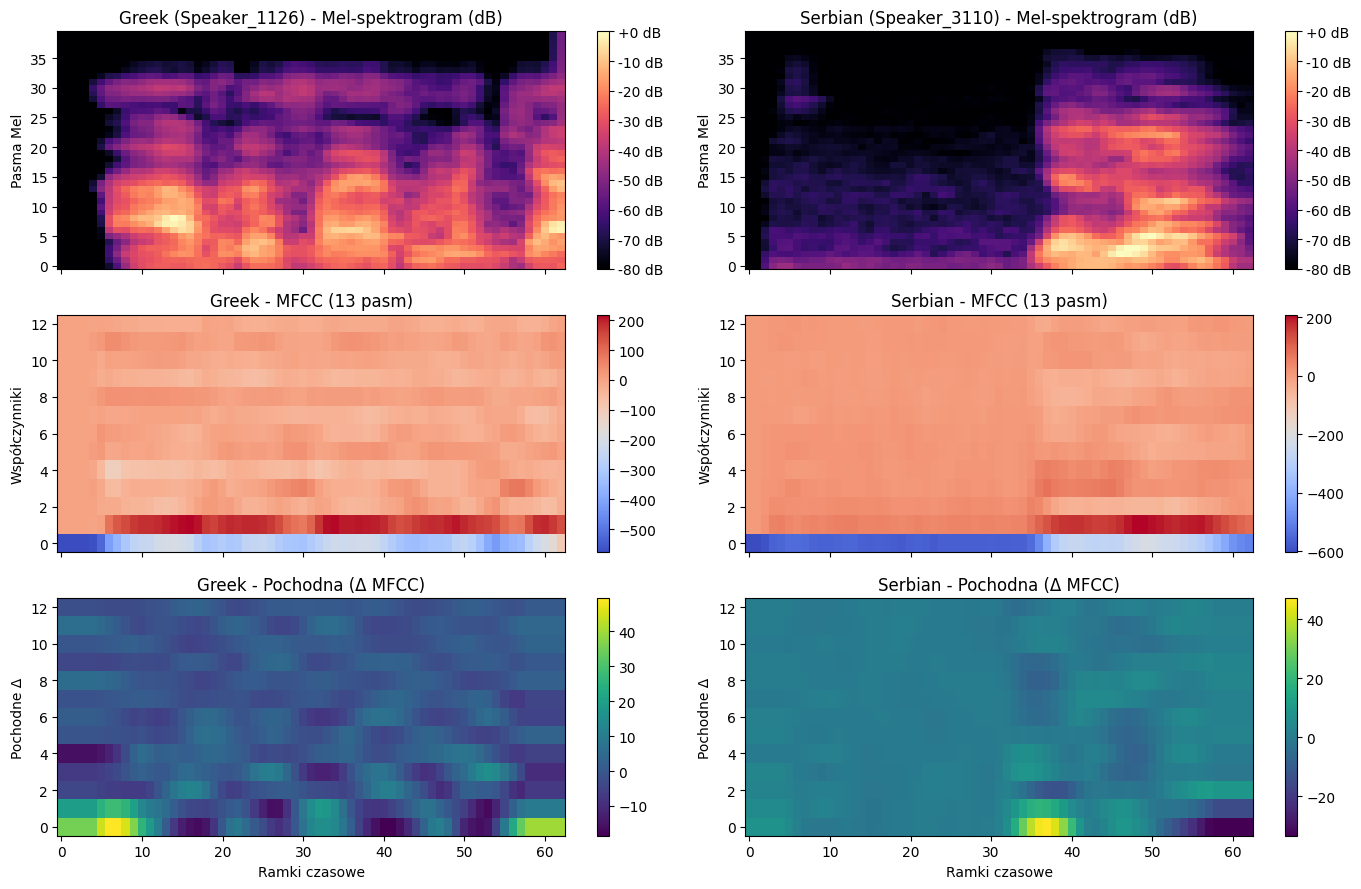

In [4]:
greek_speaker = get_speaker_by_label(raw_speakers_data, label='Greek', random_state=random_state)
serbian_speaker = get_speaker_by_label(raw_speakers_data, label='Serbian', random_state=random_state)

print(f"Lewa kolumna: {greek_speaker['label']} ({greek_speaker['speaker']})")
print(f"Prawa kolumna: {serbian_speaker['label']} ({serbian_speaker['speaker']})")

plot_spectrogram_and_mfcc_comparison(
    speaker_left=greek_speaker,
    speaker_right=serbian_speaker,
    sr=target_sr,
    n_mels=n_mels,
    n_mfcc=n_mfcc,
)


In [5]:
dataset_ml = build_spectral_feature_dataframe(
    raw_speakers_data,
    feature_type=feature_type,
    n_mfcc=n_mfcc,
    n_mels=n_mels,
    include_prosody=include_prosody,
    include_higher_order_stats=include_higher_order_stats,
    max_workers=8,
)

print(f'Kształt macierzy cech: {dataset_ml.shape} (w tym kolumny speaker i label)')
dataset_ml.head(10)


Kształt macierzy cech: (11452, 92) (w tym kolumny speaker i label)


,speaker,label,mfcc_00_mean,mfcc_00_std,mfcc_01_mean,mfcc_01_std,mfcc_02_mean,mfcc_02_std,mfcc_03_mean,mfcc_03_std,...,f0_min,f0_max,f0_range,f0_skew,f0_voiced_fraction,phonation_ratio,pause_ratio,pause_to_phonation_ratio,tempo_bpm,onset_rate
0,Speaker_0,Greek,-531.982,105.444,42.370,42.031,-12.332,25.630,19.731,26.487,...,65.113,262.176,197.063,-0.045,0.937,0.079,0.921,11.600,113.636,2.0
1,Speaker_0,Greek,-322.046,99.446,159.044,70.362,-24.234,57.845,67.107,45.192,...,68.976,388.803,319.827,1.973,0.937,0.873,0.127,0.145,125.000,6.0
2,Speaker_0,Greek,-436.443,130.911,169.081,71.331,-9.788,42.717,45.719,30.220,...,67.475,335.330,267.854,1.706,0.984,0.762,0.238,0.312,170.455,6.0
3,Speaker_1,Greek,-447.142,131.207,70.705,59.141,-6.573,17.434,28.691,33.515,...,71.485,372.876,301.391,0.646,0.968,0.349,0.651,1.864,101.351,5.0
4,Speaker_1,Greek,-332.906,61.692,144.659,52.909,0.202,26.334,56.485,25.173,...,100.656,212.471,111.815,3.453,0.984,0.841,0.159,0.189,178.571,11.0
5,Speaker_1,Greek,-491.856,91.621,108.971,69.745,3.692,27.255,24.705,18.904,...,65.001,363.442,298.441,2.466,0.889,0.333,0.667,2.000,138.889,8.0
6,Speaker_2,Greek,-470.358,171.460,98.840,94.273,-30.468,39.881,23.480,27.601,...,67.225,372.303,305.078,1.979,0.952,0.508,0.492,0.969,104.167,6.0
7,Speaker_2,Greek,-334.803,56.383,133.804,73.870,-75.996,33.284,66.833,33.943,...,65.385,320.505,255.119,1.688,0.921,0.984,0.016,0.016,104.167,6.0
8,Speaker_2,Greek,-369.968,69.465,168.785,45.166,-56.288,32.643,51.864,17.816,...,67.362,295.123,227.761,2.219,0.937,0.937,0.063,0.068,120.968,6.0
9,Speaker_3,Greek,-368.053,89.739,137.249,60.898,-17.787,24.314,25.775,29.641,...,94.719,333.859,239.141,0.941,0.952,0.857,0.143,0.167,120.968,7.0


In [6]:
print('Rozkład przed wyrównaniem:')
stats_before = get_group_statistics(dataset_ml)
display(stats_before)

dataset_balanced = balance_speaker_groups(
    dataset_ml,
    min_samples_per_speaker=1,
    max_samples_per_speaker=3,
    balance_speakers_per_class=True,
    balance_samples_per_class=True,
    random_state=random_state,
)

print('\nRozkład po wyrównaniu mówców i łącznego czasu mowy:')
stats_after = get_group_statistics(dataset_balanced)
display(stats_after)


Rozkład przed wyrównaniem:


,Zbiór,Język,Liczba mówców,Liczba próbek (1s),Łączny czas mowy (s),Śr. czas / mówca (s)
0,Całość,Greek,1984,6467,6467.0,3.26
1,Całość,Serbian,1962,4985,4985.0,2.54



Rozkład po wyrównaniu mówców i łącznego czasu mowy:


,Zbiór,Język,Liczba mówców,Liczba próbek (1s),Łączny czas mowy (s),Śr. czas / mówca (s)
0,Całość,Greek,1926,4369,4369.0,2.27
1,Całość,Serbian,1962,4369,4369.0,2.23


,Zbiór,Język,Liczba mówców,Liczba próbek (1s),Łączny czas mowy (s),Śr. czas / mówca (s)
0,Całość,Greek,1926,4369,4369.0,2.27
1,Całość,Serbian,1962,4369,4369.0,2.23
2,Trening,Serbian,1472,3280,3280.0,2.23
3,Trening,Greek,1444,3259,3259.0,2.26
4,Test,Greek,482,1110,1110.0,2.30
5,Test,Serbian,490,1089,1089.0,2.22


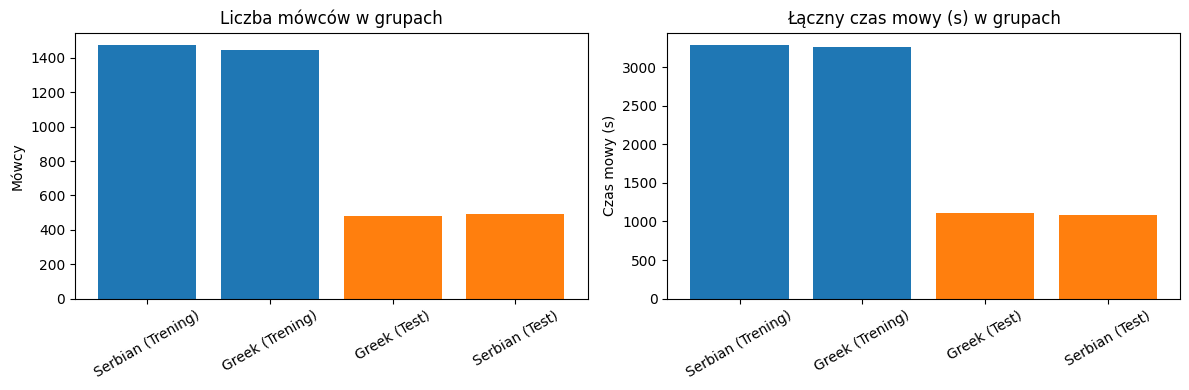

In [7]:
X_train, y_train, X_test, y_test, speakers_train, speakers_test, train_df, test_df = (
    stratified_speaker_train_test_split(
        dataset_balanced,
        test_size=0.25,
        random_state=random_state,
    )
)

split_stats = get_group_statistics(dataset_balanced, speakers_train, speakers_test)
display(split_stats)
plot_group_balance(split_stats)


Najlepsze parametry Grid Search (walidacja grupowa po mówcach): {'svm__C': 2.0, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}


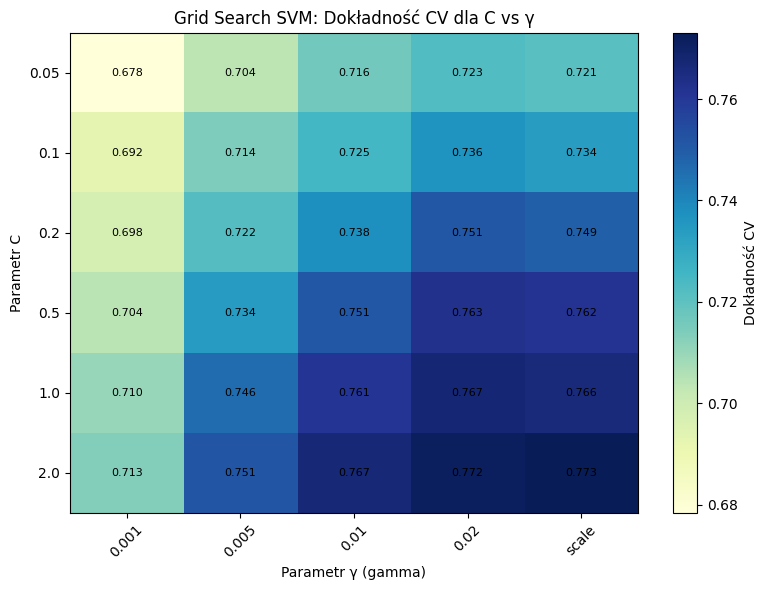

In [8]:
tuning_method = 'grid_search'  # 'grid_search' lub 'optuna'

if tuning_method == 'grid_search':
    param_grid = {
        'svm__C': [0.05, 0.1, 0.2, 0.5, 1.0, 2.0],
        'svm__gamma': [0.001, 0.005, 0.01, 0.02, 'scale'],
        'svm__kernel': ['rbf', 'linear'],
    }
    best_svm, best_params, tuning_results = tune_svm_grid_search(
        X_train=X_train,
        y_train=y_train,
        groups=train_df['speaker'],
        use_pca=use_pca,
        n_components=n_components,
        param_grid=param_grid,
        cv=5,
        random_state=random_state,
    )
    print(f'Najlepsze parametry Grid Search (walidacja grupowa po mówcach): {best_params}')
    plot_svm_grid_search(tuning_results)
else:
    best_svm, best_params, tuning_results = tune_svm_optuna(
        X_train=X_train,
        y_train=y_train,
        groups=train_df['speaker'],
        use_pca=use_pca,
        n_components=n_components,
        n_trials=25,
        cv=5,
        random_state=random_state,
    )
    print(f'Najlepsze parametry Optuna: {best_params}')


In [9]:
results = train_and_evaluate(
    model=best_svm,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    scale_features=True,
)

print('=' * 20 + ' RAPORT: ZBIÓR TRENINGOWY ' + '=' * 20)
print(results['report_train'])
print(f"Dokładność na zbiorze treningowym: {results['acc_train']:.2%}")

print('\n' + '=' * 20 + ' RAPORT: ZBIÓR TESTOWY ' + '=' * 20)
print(results['report_test'])
print(f"Dokładność na zbiorze testowym: {results['acc_test']:.2%}")
if results['roc_auc'] is not None:
    print(f"ROC-AUC na zbiorze testowym: {results['roc_auc']:.4f}")


==================== RAPORT: ZBIÓR TRENINGOWY ====================
              precision    recall  f1-score   support

       Greek       0.87      0.85      0.86      3259
     Serbian       0.85      0.88      0.86      3280

    accuracy                           0.86      6539
   macro avg       0.86      0.86      0.86      6539
weighted avg       0.86      0.86      0.86      6539

Dokładność na zbiorze treningowym: 86.16%

==================== RAPORT: ZBIÓR TESTOWY ====================
              precision    recall  f1-score   support

       Greek       0.79      0.74      0.77      1110
     Serbian       0.75      0.80      0.78      1089

    accuracy                           0.77      2199
   macro avg       0.77      0.77      0.77      2199
weighted avg       0.77      0.77      0.77      2199

Dokładność na zbiorze testowym: 77.26%
ROC-AUC na zbiorze testowym: 0.8502


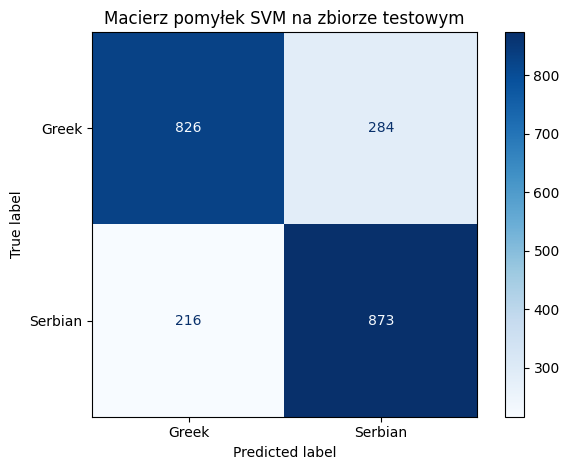

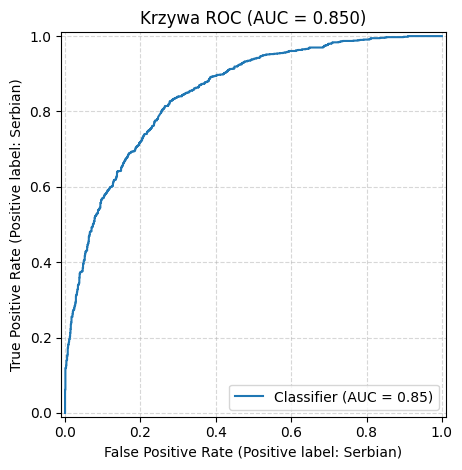

In [10]:
plot_confusion_matrix(
    cm=results['confusion_matrix'],
    classes=results['classes'],
    title='Macierz pomyłek SVM na zbiorze testowym',
)

if results['y_prob_test'] is not None:
    plot_roc_curve(
        y_true=y_test,
        y_prob=results['y_prob_test'][:, 1],
        pos_label=results['classes'][1],
        title=f"Krzywa ROC (AUC = {results['roc_auc']:.3f})",
    )


### 8. Grupowa walidacja krzyżowa (StratifiedGroupKFold) i analiza stabilności

Ocena modelu w 5-krotnej walidacji krzyżowej z podziałem grupowym wg mówców (brak wycieku mówców pomiędzy foldami).

========================= WYNIKI POSZCZEGÓLNYCH FOLDÓW =========================


,Fold,Trening Mówcy,Walidacja Mówcy,Train Accuracy,Val Accuracy,Generalization Gap,Val Precision,Val Recall,Val F1,Val ROC-AUC
0,1,3110,778,0.857,0.789,0.067,0.777,0.811,0.794,0.865
1,2,3111,777,0.861,0.773,0.087,0.755,0.810,0.781,0.852
2,3,3110,778,0.862,0.781,0.081,0.773,0.795,0.784,0.853
3,4,3111,777,0.865,0.756,0.110,0.744,0.780,0.762,0.838
4,5,3110,778,0.857,0.776,0.081,0.782,0.767,0.774,0.861



========================= PODSUMOWANIE STATYSTYCZNE WALIDACJI =========================


,Metryka,Średnia (Mean),Odch. std (Std),Min,Max,Współczynnik zmienności (CV)
0,Train Accuracy,0.860,0.004,0.857,0.865,0.004
1,Val Accuracy,0.775,0.013,0.756,0.789,0.016
2,Generalization Gap,0.085,0.015,0.067,0.110,0.181
3,Val Precision,0.766,0.016,0.744,0.782,0.021
4,Val Recall,0.793,0.019,0.767,0.811,0.024
5,Val F1,0.779,0.012,0.762,0.794,0.015
6,Val ROC-AUC,0.854,0.010,0.838,0.865,0.012



========================= ANALIZA STABILNOŚCI MODELU =========================


,Wskaźnik,Wartość
0,Średnia dokładność walidacji (Val Acc),77.51%
1,Odch. std walidacji (Val Acc Std),1.25%
2,Współczynnik zmienności dokładności (CV = std/mean),0.0161
3,Średnia luka generalizacji (Train - Val),8.51%
4,Odch. std luki generalizacji (Gap Std),1.54%
5,Średni wynik F1 (Val F1),77.90%
6,Współczynnik zmienności F1 (CV),0.0155
7,Ocena stabilności modelu,Dobra stabilność (niska tendencja do przeuczenia)


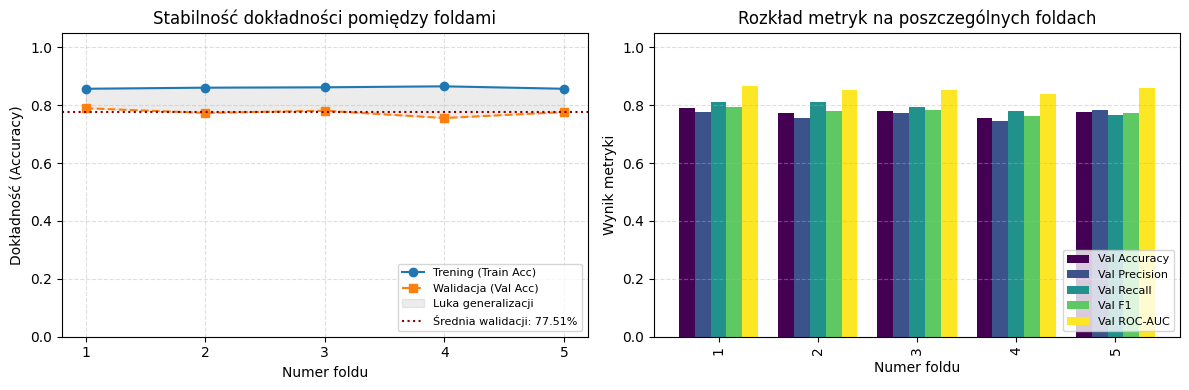

In [11]:
# 5-krotna walidacja grupowa (StratifiedGroupKFold)
cv_results = run_group_cross_validation(
    model=best_svm,
    dataset=dataset_balanced,
    n_splits=5,
    scale_features=True,
    random_state=random_state,
)

print('=' * 25 + ' WYNIKI POSZCZEGÓLNYCH FOLDÓW ' + '=' * 25)
display(cv_results['fold_results'])

print('\n' + '=' * 25 + ' PODSUMOWANIE STATYSTYCZNE WALIDACJI ' + '=' * 25)
display(cv_results['summary'])

print('\n' + '=' * 25 + ' ANALIZA STABILNOŚCI MODELU ' + '=' * 25)
display(cv_results['stability_analysis'])

plot_cv_stability(cv_results['fold_results'])


### 9. Powtórzenie eksperymentu dla kilku ziaren losowości (Multi-seed Evaluation)

Wielokrotny podział zbioru na train/test (z zachowaniem rozłączności mówców) dla ziaren: `[42, 100, 2024, 7, 999]` celem oszacowania wariancji metryk, luki generalizacji i przedziału ufności 95%.

========================= WYNIKI DLA POSZCZEGÓLNYCH ZIAREN =========================


,Seed,Liczba mówców Train,Liczba mówców Test,Train Accuracy,Test Accuracy,Generalization Gap,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,42,2916,972,0.862,0.773,0.089,0.755,0.802,0.777,0.850
1,100,2916,972,0.859,0.790,0.070,0.771,0.816,0.793,0.863
2,2024,2916,972,0.865,0.772,0.093,0.777,0.767,0.772,0.851
3,7,2916,972,0.861,0.787,0.075,0.779,0.805,0.792,0.859
4,999,2916,972,0.869,0.770,0.099,0.756,0.798,0.776,0.843



========================= PODSUMOWANIE STATYSTYCZNE ZIAREN =========================


,Metryka,Średnia (Mean),Odch. std (Std),Min,Max,Współczynnik zmienności (CV)
0,Train Accuracy,0.863,0.004,0.859,0.869,0.004
1,Test Accuracy,0.778,0.009,0.770,0.790,0.012
2,Generalization Gap,0.085,0.012,0.070,0.099,0.145
3,Test Precision,0.767,0.012,0.754,0.779,0.015
4,Test Recall,0.797,0.018,0.767,0.816,0.023
5,Test F1,0.782,0.009,0.772,0.792,0.012
6,Test ROC-AUC,0.853,0.008,0.843,0.863,0.009



========================= RAPORT ODPORNOŚCI NA LOSOWY PODZIAŁ =========================


,Wskaźnik stabilności między ziarnami,Wartość
0,Liczba zbadanych ziaren losowości (Seeds),5
1,Średnia dokładność testowa (Mean Test Acc),77.83%
2,Odchylenie standardowe dokładności (Std),0.91%
3,Przedział ufności ok. 95% (Mean ± 2 Std),[76.00%; 79.66%]
4,Współczynnik zmienności dokładności (CV),0.0118
5,Średni wynik F1 na teście (Mean F1),78.20%
6,Odchylenie F1 (Std),0.95%
7,Średnia luka generalizacji (Train - Test),8.49%
8,Ocena odporności na losowość,Wysoka odporność na ziarno losowości


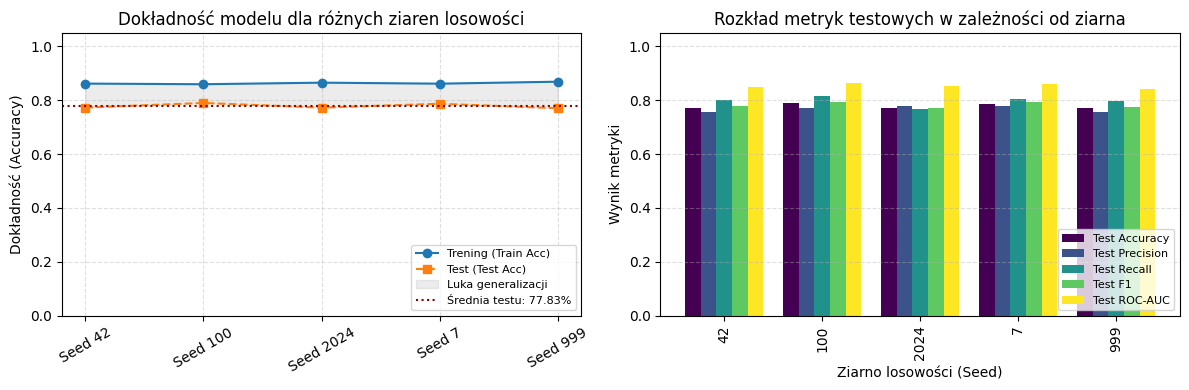

In [12]:
# Ewaluacja odporności na losowość podziału (multi-seed evaluation)
seeds_to_test = [42, 100, 2024, 7, 999]
multiseed_results = run_multiseed_experiment(
    model=best_svm,
    dataset=dataset_balanced,
    seeds=seeds_to_test,
    test_size=0.25,
    scale_features=True,
)

print('=' * 25 + ' WYNIKI DLA POSZCZEGÓLNYCH ZIAREN ' + '=' * 25)
display(multiseed_results['seed_results'])

print('\n' + '=' * 25 + ' PODSUMOWANIE STATYSTYCZNE ZIAREN ' + '=' * 25)
display(multiseed_results['summary'])

print('\n' + '=' * 25 + ' RAPORT ODPORNOŚCI NA LOSOWY PODZIAŁ ' + '=' * 25)
display(multiseed_results['stability_report'])

plot_multiseed_stability(multiseed_results['seed_results'])
